<a href="https://colab.research.google.com/github/canam8464git/mini-project-credit-card-default-prediction/blob/main/Copy_of_default_of_credit_card_clients.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:

!pip install ucimlrepo
import pandas as pd
import numpy as np


In [27]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
default_of_credit_card_clients = fetch_ucirepo(id=350)

# data (as pandas dataframes)
X = default_of_credit_card_clients.data.features
y = default_of_credit_card_clients.data.targets

# metadata
display(default_of_credit_card_clients.metadata)

# variable information
display(default_of_credit_card_clients.variables)


{'uci_id': 350,
 'name': 'Default of Credit Card Clients',
 'repository_url': 'https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients',
 'data_url': 'https://archive.ics.uci.edu/static/public/350/data.csv',
 'abstract': "This research aimed at the case of customers' default payments in Taiwan and compares the predictive accuracy of probability of default among six data mining methods.",
 'area': 'Business',
 'tasks': ['Classification'],
 'characteristics': ['Multivariate'],
 'num_instances': 30000,
 'num_features': 23,
 'feature_types': ['Integer', 'Real'],
 'demographics': ['Sex', 'Education Level', 'Marital Status', 'Age'],
 'target_col': ['Y'],
 'index_col': ['ID'],
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 2009,
 'last_updated': 'Fri Mar 29 2024',
 'dataset_doi': '10.24432/C55S3H',
 'creators': ['I-Cheng Yeh'],
 'intro_paper': {'ID': 365,
  'type': 'NATIVE',
  'title': 'The comparisons of data mining techniques for the

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,None,None,None,no
1,X1,Feature,Integer,None,LIMIT_BAL,None,no
2,X2,Feature,Integer,Sex,SEX,None,no
3,X3,Feature,Integer,Education Level,EDUCATION,None,no
4,X4,Feature,Integer,Marital Status,MARRIAGE,None,no
5,X5,Feature,Integer,Age,AGE,None,no
6,X6,Feature,Integer,None,PAY_0,None,no
7,X7,Feature,Integer,None,PAY_2,None,no
8,X8,Feature,Integer,None,PAY_3,None,no
9,X9,Feature,Integer,None,PAY_4,None,no


In [28]:
display(X.head(10))

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679
5,50000,1,1,2,37,0,0,0,0,0,0,64400,57069,57608,19394,19619,20024,2500,1815,657,1000,1000,800
6,500000,1,1,2,29,0,0,0,0,0,0,367965,412023,445007,542653,483003,473944,55000,40000,38000,20239,13750,13770
7,100000,2,2,2,23,0,-1,-1,0,0,-1,11876,380,601,221,-159,567,380,601,0,581,1687,1542
8,140000,2,3,1,28,0,0,2,0,0,0,11285,14096,12108,12211,11793,3719,3329,0,432,1000,1000,1000
9,20000,1,3,2,35,-2,-2,-2,-2,-1,-1,0,0,0,0,13007,13912,0,0,0,13007,1122,0


In [29]:

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
df_full = pd.concat([X, y], axis=1)
display(X.head(10))
display(y.head(10))

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679
5,50000,1,1,2,37,0,0,0,0,0,0,64400,57069,57608,19394,19619,20024,2500,1815,657,1000,1000,800
6,500000,1,1,2,29,0,0,0,0,0,0,367965,412023,445007,542653,483003,473944,55000,40000,38000,20239,13750,13770
7,100000,2,2,2,23,0,-1,-1,0,0,-1,11876,380,601,221,-159,567,380,601,0,581,1687,1542
8,140000,2,3,1,28,0,0,2,0,0,0,11285,14096,12108,12211,11793,3719,3329,0,432,1000,1000,1000
9,20000,1,3,2,35,-2,-2,-2,-2,-1,-1,0,0,0,0,13007,13912,0,0,0,13007,1122,0


,Y
0,1
1,1
2,0
3,0
4,0
5,0
6,0
7,0
8,0
9,0


In [30]:
print("+++Data Preprocessing+++")

#kiểm tra missing values
print("\nsố lượng giá trị thiếu ở X: ")
print(X.isnull().sum())

print("\nsố lượng giá trị thiếu y: ")
print(y.isnull().sum())

#kiểm tra trùng lặp
df = pd.concat([X, y], axis = 1)
print("\nSố lượng trùng lặp: ")
print(df.duplicated().sum())

#kiểm tra tính nhất quán
# 1. Nhóm biến phân loại: xem các giá trị duy nhất có mặt
print("--- Nhóm phân loại (X2, X3, X4) ---")
for col in ['X2', 'X3', 'X4']:
    print(f"{col}: {sorted(X[col].unique())}")

# 2. Nhóm biến trạng thái thanh toán quá khứ (X6 - X11)
pay_cols = [f'X{i}' for i in range(6, 12)]
print("\n--- Nhóm trạng thái thanh toán (X6 - X11) ---")
for col in pay_cols:
    print(f"{col}: {sorted(X[col].unique())}")

# 3. Nhóm biến số liên tục: kiểm tra min, max của hạn mức, tuổi, dư nợ, tiền thanh toán
num_cols = ['X1', 'X5'] + [f'X{i}' for i in range(12, 24)]
print("\n--- Nhóm biến số (Min / Max để rà soát bất thường) ---")
print(X[num_cols].agg(['min', 'max']).T)

+++Data Preprocessing+++

số lượng giá trị thiếu ở X: 
X1     0
X2     0
X3     0
X4     0
X5     0
X6     0
X7     0
X8     0
X9     0
X10    0
X11    0
X12    0
X13    0
X14    0
X15    0
X16    0
X17    0
X18    0
X19    0
X20    0
X21    0
X22    0
X23    0
dtype: int64

số lượng giá trị thiếu y: 
Y    0
dtype: int64

Số lượng trùng lặp: 
35
--- Nhóm phân loại (X2, X3, X4) ---
X2: [np.int64(1), np.int64(2)]
X3: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
X4: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

--- Nhóm trạng thái thanh toán (X6 - X11) ---
X6: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
X7: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
X8: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), 

In [31]:
# Kiểm tra chi tiết cột tuổi (X5): thống kê mô tả, số giá trị duy nhất và phân bố phổ biến
print("--- Thống kê mô tả X5 (AGE) ---")
print(X['X5'].describe())

print("\n--- Số lượng giá trị tuổi khác nhau có mặt ---")
print("Tổng số mức tuổi:", X['X5'].nunique())
print("Danh sách các mức tuổi (tăng dần):", sorted(X['X5'].unique()))

print("\n--- Top 10 độ tuổi xuất hiện nhiều nhất ---")
print(X['X5'].value_counts().head(10))

--- Thống kê mô tả X5 (AGE) ---
count    30000.000000
mean        35.485500
std          9.217904
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: X5, dtype: float64

--- Số lượng giá trị tuổi khác nhau có mặt ---
Tổng số mức tuổi: 56
Danh sách các mức tuổi (tăng dần): [np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.i

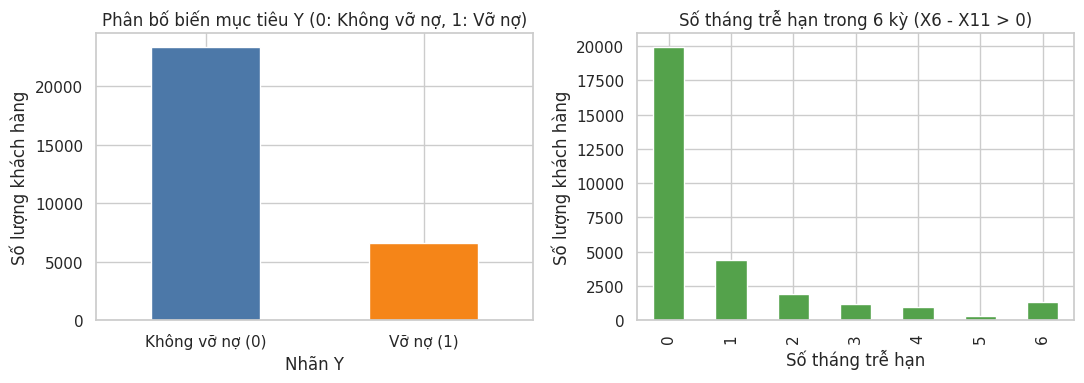

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

# --- EDA tổng quan: Phân bố biến mục tiêu Y và số kỳ trễ hạn (chạy độc lập từ dữ liệu gốc) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Lấy Series nhãn Y an toàn dù y đang là Series hay DataFrame
y_target_eda = y["Y"] if isinstance(y, pd.DataFrame) else y

# 1. Phân bố biến mục tiêu Y (0: Không vỡ nợ, 1: Vỡ nợ)
y_target_eda.value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4C78A8", "#F58518"]
)
axes[0].set_title("Phân bố biến mục tiêu Y (0: Không vỡ nợ, 1: Vỡ nợ)")
axes[0].set_xlabel("Nhãn Y")
axes[0].set_ylabel("Số lượng khách hàng")
axes[0].set_xticklabels(["Không vỡ nợ (0)", "Vỡ nợ (1)"], rotation=0)

# 2. Phân phối số tháng trễ hạn trong 6 kỳ (X6 - X11 > 0) tính trực tiếp từ X gốc
pay_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]
delayed_months_eda = (X[pay_cols] > 0).sum(axis=1)
delayed_months_eda.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color="#54A24B"
)
axes[1].set_title("Số tháng trễ hạn trong 6 kỳ (X6 - X11 > 0)")
axes[1].set_xlabel("Số tháng trễ hạn")
axes[1].set_ylabel("Số lượng khách hàng")

plt.tight_layout()
plt.show()

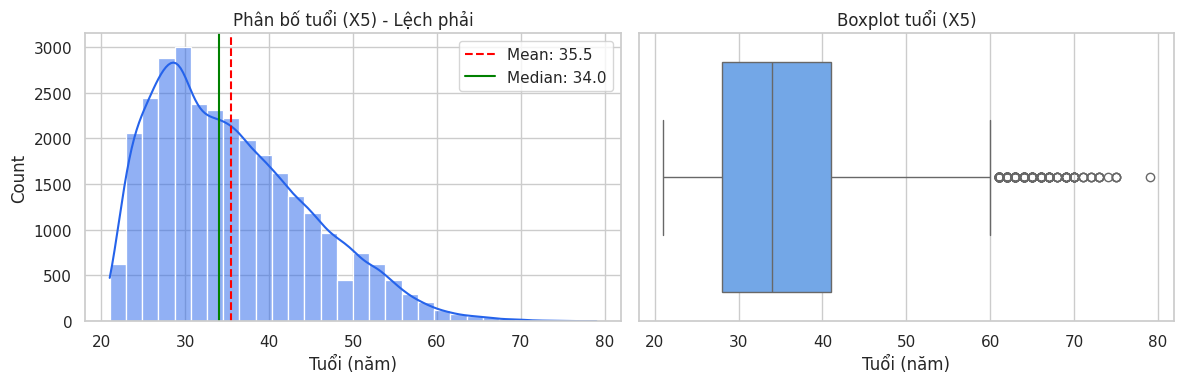

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện biểu đồ cho dễ nhìn
sns.set_theme(style="whitegrid")

# 1. Trực quan hóa cột tuổi X5: Histogram (phân bố + lệch đuôi) & Boxplot (tứ phân vị + ngoại lai)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X['X5'], bins=30, kde=True, ax=axes[0], color="#2563eb")
axes[0].axvline(X['X5'].mean(), color="red", linestyle="--", label=f"Mean: {X['X5'].mean():.1f}")
axes[0].axvline(X['X5'].median(), color="green", linestyle="-", label=f"Median: {X['X5'].median():.1f}")
axes[0].set_title("Phân bố tuổi (X5) - Lệch phải")
axes[0].set_xlabel("Tuổi (năm)")
axes[0].legend()

sns.boxplot(x=X['X5'], ax=axes[1], color="#60a5fa")
axes[1].set_title("Boxplot tuổi (X5)")
axes[1].set_xlabel("Tuổi (năm)")

plt.tight_layout()
plt.show()

In [34]:
# 1. Xóa 35 dòng trùng lặp hoàn toàn trên bảng dữ liệu gộp df và đặt lại index cho gọn
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Số dòng trước khi xóa trùng:", len(df))
print("Số dòng sau khi xóa trùng:", len(df_clean))
print("Số dòng trùng lặp còn lại:", df_clean.duplicated().sum())

Số dòng trước khi xóa trùng: 30000
Số dòng sau khi xóa trùng: 29965
Số dòng trùng lặp còn lại: 0


In [35]:
# 2. Gộp các mã ngoài quy ước chuẩn về nhóm "Khác" (Others)
# X3 (EDUCATION): chuẩn là 1, 2, 3, 4 -> gộp 0, 5, 6 về 4
df_clean['X3'] = df_clean['X3'].replace({0: 4, 5: 4, 6: 4})

# X4 (MARRIAGE): chuẩn là 1, 2, 3 -> gộp 0 về 3
df_clean['X4'] = df_clean['X4'].replace({0: 3})

print("Giá trị duy nhất của X3 sau khi gộp:", sorted(df_clean['X3'].unique()))
print("Giá trị duy nhất của X4 sau khi gộp:", sorted(df_clean['X4'].unique()))

Giá trị duy nhất của X3 sau khi gộp: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Giá trị duy nhất của X4 sau khi gộp: [np.int64(1), np.int64(2), np.int64(3)]


In [36]:
from sklearn.model_selection import train_test_split

# 1. Tách riêng bảng đặc trưng X_clean (23 cột) và nhãn mục tiêu y_clean (cột Y) từ df_clean
X_clean = df_clean.drop(columns=['Y'])
y_clean = df_clean['Y']

# 2. Chia dữ liệu thành 80% train và 20% test
# random_state=42 giúp cố định cách chia để lần chạy sau kết quả giống hệt nhau
# stratify=y_clean giữ tỷ lệ lớp Y ở train và test sát với dữ liệu gốc
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean
)

# 3. Kiểm tra nhanh kích thước và tỷ lệ phân bố nhãn sau khi chia
print("X_train shape:", X_train.shape, "| y_train shape:", y_train.shape)
print("X_test shape: ", X_test.shape,  "| y_test shape: ", y_test.shape)
print("\nTỷ lệ nhãn Y trong y_train:\n", y_train.value_counts(normalize=True).round(4))
print("\nTỷ lệ nhãn Y trong y_test:\n", y_test.value_counts(normalize=True).round(4))

X_train shape: (23972, 23) | y_train shape: (23972,)
X_test shape:  (5993, 23) | y_test shape:  (5993,)

Tỷ lệ nhãn Y trong y_train:
 Y
0    0.7787
1    0.2213
Name: proportion, dtype: float64

Tỷ lệ nhãn Y trong y_test:
 Y
0    0.7787
1    0.2213
Name: proportion, dtype: float64


In [37]:
from sklearn.preprocessing import StandardScaler

# 1. Khởi tạo bộ chuẩn hóa thang đo
scaler = StandardScaler()

# 2. Học trung bình & độ lệch chuẩn từ X_train rồi biến đổi X_train
X_train_scaled = scaler.fit_transform(X_train)

# 3. Áp dụng đúng thông số đã học từ X_train để biến đổi X_test
X_test_scaled = scaler.transform(X_test)

# 4. Kiểm tra lại kích thước và giá trị trung bình/độ lệch chuẩn sau khi scale trên tập train
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape: ", X_test_scaled.shape)
print("Mean gần 0 (lấy mẫu cột đầu):", round(X_train_scaled[:, 0].mean(), 4))
print("Std gần 1 (lấy mẫu cột đầu): ", round(X_train_scaled[:, 0].std(), 4))

X_train_scaled shape: (23972, 23)
X_test_scaled shape:  (5993, 23)
Mean gần 0 (lấy mẫu cột đầu): 0.0
Std gần 1 (lấy mẫu cột đầu):  1.0


In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# 1. Khởi tạo mô hình Logistic Regression nền tảng
# max_iter=1000 giúp thuật toán tối ưu có đủ số bước để hội tụ
model = LogisticRegression(max_iter=1000, random_state=42)

# 2. Huấn luyện mô hình trên tập train đã chuẩn hóa và nhãn y_train
model.fit(X_train_scaled, y_train)

# 3. Dự đoán nhãn (0/1) và xác suất thuộc lớp 1 trên tập test
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# 4. Đánh giá nhanh kết quả trên tập test
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

Accuracy: 0.8133
ROC-AUC:  0.716

Classification Report:
               precision    recall  f1-score   support

           0     0.8203    0.9734    0.8903      4667
           1     0.7275    0.2496    0.3717      1326

    accuracy                         0.8133      5993
   macro avg     0.7739    0.6115    0.6310      5993
weighted avg     0.7998    0.8133    0.7756      5993



In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# 1. Khởi tạo và huấn luyện Logistic Regression nền tảng
lr_base = LogisticRegression(max_iter=1000, random_state=42)
lr_base.fit(X_train_scaled, y_train)

# 2. Dự đoán nhãn và xác suất vỡ nợ (lớp 1) trên tập test
y_pred_lr_base = lr_base.predict(X_test_scaled)
y_prob_lr_base = lr_base.predict_proba(X_test_scaled)[:, 1]

# 3. Đánh giá kết quả
print("=== LogisticRegression (baseline) ===")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr_base), 4))
print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob_lr_base), 4))
print(classification_report(y_test, y_pred_lr_base, digits=4))

=== LogisticRegression (baseline) ===
Accuracy: 0.8133
ROC-AUC:  0.716
              precision    recall  f1-score   support

           0     0.8203    0.9734    0.8903      4667
           1     0.7275    0.2496    0.3717      1326

    accuracy                         0.8133      5993
   macro avg     0.7739    0.6115    0.6310      5993
weighted avg     0.7998    0.8133    0.7756      5993



In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Huấn luyện lại Logistic Regression có cân bằng trọng số lớp
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
lr_bal.fit(X_train_scaled, y_train)

# Dự đoán nhãn và xác suất lớp 1 trên tập test
y_pred_lr_bal = lr_bal.predict(X_test_scaled)
y_prob_lr_bal = lr_bal.predict_proba(X_test_scaled)[:, 1]

# Đánh giá kết quả
print("=== LogisticRegression (class_weight='balanced') ===")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr_bal), 4))
print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob_lr_bal), 4))
print(classification_report(y_test, y_pred_lr_bal, digits=4))

=== LogisticRegression (class_weight='balanced') ===
Accuracy: 0.6856
ROC-AUC:  0.7164
              precision    recall  f1-score   support

           0     0.8684    0.7028    0.7769      4667
           1     0.3741    0.6252    0.4681      1326

    accuracy                         0.6856      5993
   macro avg     0.6213    0.6640    0.6225      5993
weighted avg     0.7590    0.6856    0.7086      5993



In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# 1. Khởi tạo Random Forest có cân bằng trọng số lớp
rf_bal = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

# 2. Huấn luyện trên tập dữ liệu đã chuẩn hóa (đồng bộ với các bước trước)
rf_bal.fit(X_train_scaled, y_train)

# 3. Dự đoán nhãn và xác suất vỡ nợ (lớp 1) trên tập test
y_pred_rf_bal = rf_bal.predict(X_test_scaled)
y_prob_rf_bal = rf_bal.predict_proba(X_test_scaled)[:, 1]

# 4. In kết quả đánh giá
print("=== RandomForestClassifier (class_weight='balanced') ===")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_bal), 4))
print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob_rf_bal), 4))
print(classification_report(y_test, y_pred_rf_bal, digits=4))

=== RandomForestClassifier (class_weight='balanced') ===
Accuracy: 0.8118
ROC-AUC:  0.7609
              precision    recall  f1-score   support

           0     0.8344    0.9460    0.8867      4667
           1     0.6410    0.3394    0.4438      1326

    accuracy                         0.8118      5993
   macro avg     0.7377    0.6427    0.6653      5993
weighted avg     0.7916    0.8118    0.7887      5993



In [42]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight

# 1. Tính trọng số cho từng mẫu train để tăng mức phạt cho lớp 1 (vỡ nợ)
sample_weights_train = compute_sample_weight(class_weight="balanced", y=y_train)

# 2. Khởi tạo và huấn luyện HistGradientBoostingClassifier
hgb_bal = HistGradientBoostingClassifier(random_state=42)
hgb_bal.fit(X_train_scaled, y_train, sample_weight=sample_weights_train)

# 3. Dự đoán nhãn và xác suất vỡ nợ (lớp 1) trên tập test
y_pred_hgb_bal = hgb_bal.predict(X_test_scaled)
y_prob_hgb_bal = hgb_bal.predict_proba(X_test_scaled)[:, 1]

# 4. In kết quả đánh giá
print("=== HistGradientBoostingClassifier (balanced sample_weight) ===")
print("Accuracy:", round(accuracy_score(y_test, y_pred_hgb_bal), 4))
print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob_hgb_bal), 4))
print(classification_report(y_test, y_pred_hgb_bal, digits=4))

=== HistGradientBoostingClassifier (balanced sample_weight) ===
Accuracy: 0.7494
ROC-AUC:  0.7739
              precision    recall  f1-score   support

           0     0.8814    0.7836    0.8296      4667
           1     0.4523    0.6290    0.5262      1326

    accuracy                         0.7494      5993
   macro avg     0.6668    0.7063    0.6779      5993
weighted avg     0.7865    0.7494    0.7625      5993



In [43]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

# Danh sách các mô hình đã thử nghiệm trên tập test
experiments = [
    ("LogReg (baseline)", y_pred_lr_base, y_prob_lr_base),
    ("LogReg (balanced)", y_pred_lr_bal, y_prob_lr_bal),
    ("RandomForest (balanced)", y_pred_rf_bal, y_prob_rf_bal),
    ("HistGradientBoosting (balanced)", y_pred_hgb_bal, y_prob_hgb_bal),
]

summary_rows = []
for name, y_pred, y_prob in experiments:
    summary_rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
        "Precision (1)": round(precision_score(y_test, y_pred, pos_label=1), 4),
        "Recall (1)": round(recall_score(y_test, y_pred, pos_label=1), 4),
        "F1-score (1)": round(f1_score(y_test, y_pred, pos_label=1), 4),
    })

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

,Model,Accuracy,ROC-AUC,Precision (1),Recall (1),F1-score (1)
0,LogReg (baseline),0.8133,0.7160,0.7275,0.2496,0.3717
1,LogReg (balanced),0.6856,0.7164,0.3741,0.6252,0.4681
2,RandomForest (balanced),0.8118,0.7609,0.6410,0.3394,0.4438
3,HistGradientBoosting (balanced),0.7494,0.7739,0.4523,0.6290,0.5262


In [44]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Copy dữ liệu đặc trưng gốc để tránh làm hỏng biến X ban đầu
X_fe = X.copy()

# 2. Tỷ lệ sử dụng hạn mức kỳ gần nhất (dư nợ X12 / hạn mức X1)
X_fe["util_ratio_1"] = X_fe["X12"] / X_fe["X1"].replace(0, np.nan)
X_fe["util_ratio_1"] = X_fe["util_ratio_1"].fillna(0)

# 3. Tỷ lệ thanh toán kỳ gần nhất so với dư nợ kỳ trước (X18 / X13)
X_fe["pay_ratio_1"] = np.where(X_fe["X13"] > 0, X_fe["X18"] / X_fe["X13"], 0)
X_fe["pay_ratio_1"] = np.clip(X_fe["pay_ratio_1"], 0, 5)  # hạn chế giá trị đột biến quá lớn

# 4. Tổng hợp hành vi trễ hạn trong 6 tháng (X6 - X11): số tháng trễ (> 0) và mức trễ lớn nhất
pay_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]
X_fe["delayed_months"] = (X_fe[pay_cols] > 0).sum(axis=1)
X_fe["max_delay"] = X_fe[pay_cols].max(axis=1)

# 5. Chuyển y về Series 1D nếu đang là DataFrame (như y.head(10) ở cell [8])
y_target = y["Y"] if isinstance(y, pd.DataFrame) else y

# 6. Chia train/test (80/20 có stratify) và chuẩn hóa trên tập đặc trưng mới
X_tr_fe, X_te_fe, y_tr_fe, y_te_fe = train_test_split(
    X_fe, y_target, test_size=0.2, random_state=42, stratify=y_target
)

scaler_fe = StandardScaler()
X_tr_fe_scaled = scaler_fe.fit_transform(X_tr_fe)
X_te_fe_scaled = scaler_fe.transform(X_te_fe)

print("Số đặc trưng trước:", X.shape[1], "-> Sau Feature Engineering:", X_fe.shape[1])
print("Các cột mới thêm:", ["util_ratio_1", "pay_ratio_1", "delayed_months", "max_delay"])

Số đặc trưng trước: 23 -> Sau Feature Engineering: 27
Các cột mới thêm: ['util_ratio_1', 'pay_ratio_1', 'delayed_months', 'max_delay']


In [45]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight

# Tính trọng số cân bằng lớp cho tập train mới
sw_fe = compute_sample_weight(class_weight="balanced", y=y_tr_fe)

hgb_fe = HistGradientBoostingClassifier(random_state=42)
hgb_fe.fit(X_tr_fe_scaled, y_tr_fe, sample_weight=sw_fe)

y_pred_hgb_fe = hgb_fe.predict(X_te_fe_scaled)
y_prob_hgb_fe = hgb_fe.predict_proba(X_te_fe_scaled)[:, 1]

print("=== HistGradientBoosting (balanced + Feature Engineering) ===")
print("Accuracy:", round(accuracy_score(y_te_fe, y_pred_hgb_fe), 4))
print("ROC-AUC: ", round(roc_auc_score(y_te_fe, y_prob_hgb_fe), 4))
print(classification_report(y_te_fe, y_pred_hgb_fe, digits=4))

=== HistGradientBoosting (balanced + Feature Engineering) ===
Accuracy: 0.7573
ROC-AUC:  0.7778
              precision    recall  f1-score   support

           0     0.8811    0.7958    0.8363      4673
           1     0.4637    0.6217    0.5312      1327

    accuracy                         0.7573      6000
   macro avg     0.6724    0.7088    0.6838      6000
weighted avg     0.7888    0.7573    0.7688      6000



In [46]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# Dùng xác suất lớp 1 từ mô hình HistGradientBoosting sau Feature Engineering
thresholds = [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]
thresh_rows = []

for th in thresholds:
    # Áp dụng ngưỡng xác suất tùy chỉnh thay vì mặc định 0.50
    y_pred_th = (y_prob_hgb_fe >= th).astype(int)
    thresh_rows.append({
        "Threshold": th,
        "Accuracy": round(accuracy_score(y_te_fe, y_pred_th), 4),
        "Precision (1)": round(precision_score(y_te_fe, y_pred_th, pos_label=1, zero_division=0), 4),
        "Recall (1)": round(recall_score(y_te_fe, y_pred_th, pos_label=1, zero_division=0), 4),
        "F1-score (1)": round(f1_score(y_te_fe, y_pred_th, pos_label=1, zero_division=0), 4),
    })

df_thresh = pd.DataFrame(thresh_rows)
display(df_thresh)

# In ra ngưỡng đạt F1-score (1) cao nhất
best_row = df_thresh.loc[df_thresh["F1-score (1)"].idxmax()]
print("\nNgưỡng cho F1-score (1) cao nhất:", dict(best_row))

,Threshold,Accuracy,Precision (1),Recall (1),F1-score (1)
0,0.35,0.6152,0.3421,0.8018,0.4796
1,0.40,0.6683,0.3733,0.7362,0.4954
2,0.45,0.7165,0.4141,0.6790,0.5144
3,0.50,0.7573,0.4637,0.6217,0.5312
4,0.55,0.7822,0.5066,0.5780,0.5400
5,0.60,0.7970,0.5422,0.5283,0.5351
6,0.65,0.8063,0.5773,0.4642,0.5146



Ngưỡng cho F1-score (1) cao nhất: {'Threshold': np.float64(0.55), 'Accuracy': np.float64(0.7822), 'Precision (1)': np.float64(0.5066), 'Recall (1)': np.float64(0.578), 'F1-score (1)': np.float64(0.54)}


In [47]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

# 1. Logistic Regression (balanced) trên tập đặc trưng mới
lr_fe = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
lr_fe.fit(X_tr_fe_scaled, y_tr_fe)
y_pred_lr_fe = lr_fe.predict(X_te_fe_scaled)
y_prob_lr_fe = lr_fe.predict_proba(X_te_fe_scaled)[:, 1]

# 2. Random Forest (balanced) trên tập đặc trưng mới
rf_fe = RandomForestClassifier(
    n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1
)
rf_fe.fit(X_tr_fe_scaled, y_tr_fe)
y_pred_rf_fe = rf_fe.predict(X_te_fe_scaled)
y_prob_rf_fe = rf_fe.predict_proba(X_te_fe_scaled)[:, 1]

# 3. Bảng so sánh công bằng trên cùng tập test sau Feature Engineering (y_te_fe)
fe_models = [
    ("LogReg (balanced + FE)", y_pred_lr_fe, y_prob_lr_fe),
    ("RandomForest (balanced + FE)", y_pred_rf_fe, y_prob_rf_fe),
    ("HistGradientBoosting (balanced + FE, th=0.50)", y_pred_hgb_fe, y_prob_hgb_fe),
    (
        "HistGradientBoosting (balanced + FE, th=0.55)",
        (y_prob_hgb_fe >= 0.55).astype(int),
        y_prob_hgb_fe,
    ),
]

df_fe_compare = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": round(accuracy_score(y_te_fe, pred), 4),
        "ROC-AUC": round(roc_auc_score(y_te_fe, prob), 4),
        "Precision (1)": round(precision_score(y_te_fe, pred, pos_label=1, zero_division=0), 4),
        "Recall (1)": round(recall_score(y_te_fe, pred, pos_label=1, zero_division=0), 4),
        "F1-score (1)": round(f1_score(y_te_fe, pred, pos_label=1, zero_division=0), 4),
    }
    for name, pred, prob in fe_models
])

display(df_fe_compare)

,Model,Accuracy,ROC-AUC,Precision (1),Recall (1),F1-score (1)
0,LogReg (balanced + FE),0.7437,0.7443,0.4421,0.6066,0.5114
1,RandomForest (balanced + FE),0.8125,0.7622,0.6439,0.3406,0.4455
2,"HistGradientBoosting (balanced + FE, th=0.50)",0.7573,0.7778,0.4637,0.6217,0.5312
3,"HistGradientBoosting (balanced + FE, th=0.55)",0.7822,0.7778,0.5066,0.5780,0.5400


PR-AUC (lớp 1): 0.5544


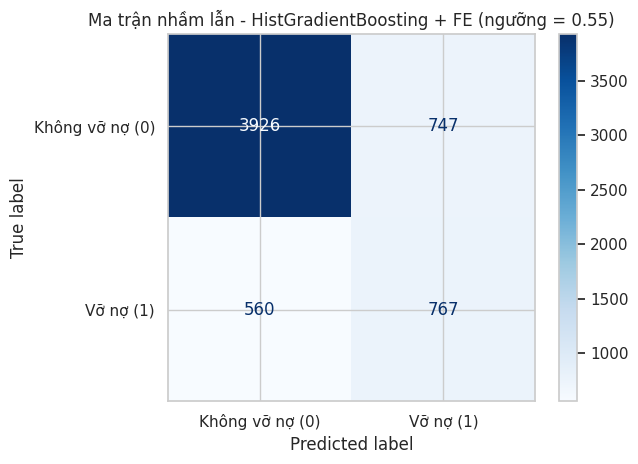

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, confusion_matrix

best_th = 0.55
y_pred_best = (y_prob_hgb_fe >= best_th).astype(int)

# 1. Tính PR-AUC (Average Precision) cho lớp 1 (vỡ nợ)
pr_auc = average_precision_score(y_te_fe, y_prob_hgb_fe)
print(f"PR-AUC (lớp 1): {pr_auc:.4f}")

# 2. Vẽ ma trận nhầm lẫn tại ngưỡng 0.55
cm = confusion_matrix(y_te_fe, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Không vỡ nợ (0)", "Vỡ nợ (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Ma trận nhầm lẫn - HistGradientBoosting + FE (ngưỡng = {best_th})")
plt.tight_layout()
plt.show()

In [49]:
def demo_predict_default(row_idx, threshold=0.55):
    """Dự đoán xác suất vỡ nợ cho một hồ sơ trong tập kiểm thử X_te_fe."""
    # Giữ dạng DataFrame 1 dòng để bảo toàn tên cột khi đưa qua scaler_fe
    sample_raw = X_te_fe.iloc[[row_idx]]
    sample_scaled = scaler_fe.transform(sample_raw)

    # Dự đoán xác suất vỡ nợ (lớp 1) từ mô hình HistGradientBoosting sau FE
    prob_default = float(hgb_fe.predict_proba(sample_scaled)[0, 1])
    pred_label = int(prob_default >= threshold)
    actual_label = int(y_te_fe.iloc[row_idx])

    print(f"Hồ sơ test index: {X_te_fe.index[row_idx]}")
    print(
        f"  - Hạn mức (X1): {int(sample_raw['X1'].iloc[0]):,} | "
        f"Dư nợ kỳ gần nhất (X12): {int(sample_raw['X12'].iloc[0]):,}"
    )
    print(
        f"  - Tỷ lệ dùng hạn mức: {sample_raw['util_ratio_1'].iloc[0]:.2f} | "
        f"Số tháng trễ hạn: {int(sample_raw['delayed_months'].iloc[0])}"
    )
    print(f"  - Xác suất vỡ nợ dự đoán: {prob_default:.4f} (Ngưỡng: {threshold})")
    print(
        f"  - Cảnh báo: {'CẢNH BÁO VỠ NỢ (1)' if pred_label == 1 else 'BÌNH THƯỜNG (0)'} "
        f"| Nhãn thực tế: {actual_label}\n"
    )


print("=== DEMO DỰ ĐOÁN MẪU ===")
demo_predict_default(0, threshold=0.55)
demo_predict_default(1, threshold=0.55)

=== DEMO DỰ ĐOÁN MẪU ===
Hồ sơ test index: 6907
  - Hạn mức (X1): 50,000 | Dư nợ kỳ gần nhất (X12): 1,540
  - Tỷ lệ dùng hạn mức: 0.03 | Số tháng trễ hạn: 0
  - Xác suất vỡ nợ dự đoán: 0.2570 (Ngưỡng: 0.55)
  - Cảnh báo: BÌNH THƯỜNG (0) | Nhãn thực tế: 0

Hồ sơ test index: 24575
  - Hạn mức (X1): 150,000 | Dư nợ kỳ gần nhất (X12): 15,000
  - Tỷ lệ dùng hạn mức: 0.10 | Số tháng trễ hạn: 0
  - Xác suất vỡ nợ dự đoán: 0.3674 (Ngưỡng: 0.55)
  - Cảnh báo: BÌNH THƯỜNG (0) | Nhãn thực tế: 0



In [50]:
# --- Thêm demo cho vài hồ sơ có nhãn thực tế vỡ nợ (y_te_fe == 1) trong tập test ---
default_positions = [
    i for i, val in enumerate(y_te_fe) if int(val) == 1
][:3]  # Lấy tối đa 3 vị trí (0-based) có nhãn thực tế là 1

print("=== DEMO THÊM HỒ SƠ VỠ NỢ THỰC TẾ (Y = 1) ===")
for pos in default_positions:
    demo_predict_default(pos, threshold=0.55)

=== DEMO THÊM HỒ SƠ VỠ NỢ THỰC TẾ (Y = 1) ===
Hồ sơ test index: 2156
  - Hạn mức (X1): 290,000 | Dư nợ kỳ gần nhất (X12): 305,823
  - Tỷ lệ dùng hạn mức: 1.05 | Số tháng trễ hạn: 0
  - Xác suất vỡ nợ dự đoán: 0.3559 (Ngưỡng: 0.55)
  - Cảnh báo: BÌNH THƯỜNG (0) | Nhãn thực tế: 1

Hồ sơ test index: 20842
  - Hạn mức (X1): 180,000 | Dư nợ kỳ gần nhất (X12): 0
  - Tỷ lệ dùng hạn mức: 0.00 | Số tháng trễ hạn: 0
  - Xác suất vỡ nợ dự đoán: 0.5898 (Ngưỡng: 0.55)
  - Cảnh báo: CẢNH BÁO VỠ NỢ (1) | Nhãn thực tế: 1

Hồ sơ test index: 3054
  - Hạn mức (X1): 350,000 | Dư nợ kỳ gần nhất (X12): 0
  - Tỷ lệ dùng hạn mức: 0.00 | Số tháng trễ hạn: 1
  - Xác suất vỡ nợ dự đoán: 0.7405 (Ngưỡng: 0.55)
  - Cảnh báo: CẢNH BÁO VỠ NỢ (1) | Nhãn thực tế: 1

